# 01 - Quickstart: three policies on a toy pool

**The situation.** You have a model, a pool of 2,000 candidate compounds, and
room for 96 wells per round. You can run six rounds. Which 96 do you pick?

The default answer is *greedy*: take the 96 highest predictions. This notebook
shows what greedy costs you, using a synthetic pool where we know every answer
in advance so we can score the choices.

**What you will see:** greedy wins the first few rounds decisively, then its
productivity collapses, because it has spent every well confirming what the
model already believed.

In [1]:
import sys
from pathlib import Path

# Figures and tables land in results/ so the committed notebooks and the README
# reference the same files.
ROOT = Path.cwd()
if not (ROOT / "loopwise").exists():
    ROOT = ROOT.parent
FIGDIR = ROOT / "results" / "figures"
TABDIR = ROOT / "results" / "tables"
FIGDIR.mkdir(parents=True, exist_ok=True)
TABDIR.mkdir(parents=True, exist_ok=True)
print("loopwise", __import__("loopwise").__version__, "| figures ->", FIGDIR)

loopwise 0.1.0 | figures -> /home/user/loopwise/results/figures


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

from loopwise import Campaign, available_policies
from loopwise.datasets import make_synthetic_pool
from loopwise.replay import compare_policies, plot_comparison

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
print("policies available:", available_policies())

policies available: ['random', 'greedy', 'uncertainty', 'bald', 'expected_model_change', 'diversity', 'kdpp', 'thompson', 'hybrid']


## The pool

Two properties of this synthetic pool are deliberate, because they are what
make real screening hard:

1. **Compounds come in clusters.** Real libraries are built from analogue
   series -- dozens of variations on one scaffold. This is why a diversity
   constraint can matter: the top 96 by any score are often near-duplicates,
   so you have bought one measurement 96 times.
2. **The hit rate is 5%.** Activity depends on a few features plus noise. At
   this rate, a greedy batch that finds 20 hits looks like a triumph while
   teaching the model almost nothing.

In [3]:
pool, info = make_synthetic_pool(
    n_items=2000, n_features=20, hit_rate=0.05, n_clusters=12, seed=0
)
feature_cols = info["feature_cols"]
truth = dict(zip(pool["item_id"], pool["label"], strict=True))

print(f"{info['n_compounds']} compounds, {info['n_actives']} actives "
      f"({info['hit_rate']:.1%} hit rate), {info['n_clusters']} structural clusters")
print(f"activity depends on features {info['informative_features']} of 20")
pool[["item_id", "cluster", "label"] + feature_cols[:4]].head()

2000 compounds, 100 actives (5.0% hit rate), 12 structural clusters
activity depends on features [6, 8, 11, 14] of 20


,item_id,cluster,label,f0,f1,f2,f3
0,CPD00000,5,1,1.697133,2.108285,-1.766798,-3.324725
1,CPD00001,7,0,0.662818,0.016989,1.093103,-0.477645
2,CPD00002,9,0,0.206961,-3.536806,0.397406,-0.064781
3,CPD00003,7,0,0.210679,1.974126,1.451048,0.915674
4,CPD00004,5,0,2.628960,2.430577,-0.217182,-3.993999


## Driving one campaign by hand

This is the whole API. `select()` returns the rows to run plus *why each was
chosen*; `observe()` feeds measurements back; `report()` summarizes.

Note what the `pool` we hand to `Campaign` does **not** contain: the `label`
column. The campaign is blind, exactly as it would be in a lab, and we play the
role of the assay by looking answers up in `truth`.

In [4]:
blind_pool = pool.drop(columns=["label", "latent_activity"])

campaign = Campaign(
    pool=blind_pool,
    model=RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
    budget=96,
    policy="hybrid",
    feature_cols=feature_cols,
    id_col="item_id",
    n_rounds_planned=6,
    seed=0,
)

batch = campaign.select()
print(batch.explain())

Round 1: 96 compound(s) selected by policy 'diversity (seeding)'.
Selecting 96 compound(s); binding constraint: well budget.
Requested budget 96; well budget 96; 80 usable wells per plate.
Estimated cost: 96 compounds in 96 wells on 2 plate(s): 0.00 acquisition + 0.00 plate = 0.00 USD
Cost: 96 compounds in 96 wells on 2 plate(s): 0.00 acquisition + 0.00 plate = 0.00 USD
96-well (8x12 = 96 wells): 8 positive + 8 negative control wells, edge ring in use, 80 wells available for samples.
96 sample wells across 2 plate(s); controls intact: True.
Edge wells are 25% of available sample wells; highest-score stratum edge enrichment vs chance 1.0 (balanced). With 96 samples in 4 strata this ratio is coarse -- one well either way moves it noticeably.


Round 1 used the **seeding policy**, not the hybrid policy we asked for. With
no measurements there is nothing to train on, so there is no model to exploit
and no uncertainty to explore -- the only sensible objective is to cover the
feature space. Loopwise does that automatically and tells you it did, rather
than fitting a model to nothing.

### Why each compound was chosen

The reason columns are the point. Six months from now, "why was this compound
on my plate?" is answerable from this CSV alone.

In [5]:
cols = ["item_id", "rank", "posterior_mean", "posterior_std", "reason"]
batch.frame[cols].head(5).style.set_properties(subset=["reason"], **{"width": "520px"})

,item_id,rank,posterior_mean,posterior_std,reason
326,CPD00326,1,0.000000,0.000000,"pick 1/96 by facility_location: marginal gain 340.9, predicted score 0.0000, max similarity to an earlier pick 0.000"
660,CPD00660,2,0.000000,0.000000,"pick 2/96 by facility_location: marginal gain 282.3, predicted score 0.0000, max similarity to an earlier pick -0.406"
1660,CPD01660,3,0.000000,0.000000,"pick 3/96 by facility_location: marginal gain 200.3, predicted score 0.0000, max similarity to an earlier pick 0.036"
1528,CPD01528,4,0.000000,0.000000,"pick 4/96 by facility_location: marginal gain 167.8, predicted score 0.0000, max similarity to an earlier pick -0.069"
1603,CPD01603,5,0.000000,0.000000,"pick 5/96 by facility_location: marginal gain 128.9, predicted score 0.0000, max similarity to an earlier pick 0.257"


In [6]:
# Play the assay: look up the true labels for the selected compounds.
results = pd.DataFrame({
    "item_id": batch.frame["item_id"],
    "label": [truth[i] for i in batch.frame["item_id"]],
})
campaign.observe(results)
print(f"round 1: {int(results['label'].sum())} hits in {len(results)} wells "
      f"({results['label'].mean():.1%})")

round 1: 9 hits in 96 wells (9.4%)


In [7]:
# Rounds 2-6.
for _ in range(5):
    batch = campaign.select()
    results = pd.DataFrame({
        "item_id": batch.frame["item_id"],
        "label": [truth[i] for i in batch.frame["item_id"]],
    })
    campaign.observe(results)
    alpha = batch.diagnostics.get("alpha")
    print(f"round {batch.round_index + 1}: {int(results['label'].sum()):>3} hits "
          f"({results['label'].mean():>5.1%})"
          + (f", alpha={alpha:.2f}" if alpha else ""))

round 2:  50 hits (52.1%), alpha=0.50


round 3:  19 hits (19.8%), alpha=0.60


round 4:  11 hits (11.5%), alpha=0.70


round 5:   7 hits ( 7.3%), alpha=0.80


round 6:   3 hits ( 3.1%), alpha=0.90


## The report

`report()` gives the three things worth tracking. Passing `oracle_labels` is
only possible here because this is a simulation -- in a live campaign you do
not know the answers, and Loopwise says so instead of inventing a regret curve.

**Regret** is how many hits a perfectly informed oracle would have found by now
minus how many you did find.

**Calibration drift** is the one people forget. Every round, the model is
retrained on a sample *it chose itself* -- the opposite of a random sample. That
bends calibration predictably: a model fed its own confident picks becomes
over-confident. Expected calibration error (ECE) catches this while accuracy
does not.

**Batch diversity** is mean pairwise distance within the batch, in units of the
pool's own spread. 1.0 means "as spread out as two random compounds"; 0.4 means
you bought a lot of near-duplicates.

In [8]:
report = campaign.report(oracle_labels=truth)
print(report.summary())

6 round(s), 576 compounds measured, 99 hit(s).
Hit rate by round: R1=9.4%, R2=52.1%, R3=19.8%, R4=11.5%, R5=7.3%, R6=3.1%
Cumulative hits: [9, 59, 78, 89, 96, 99]
Fraction of achievable hits found: 99.0%
Calibration error (ECE) 0.094 -> 0.123 (worsening).
Batch diversity (1.0 = two random pool members): R1=0.95, R2=0.68, R3=0.64, R4=0.77, R5=0.80, R6=0.89
Hybrid alpha by round: R2=0.50, R3=0.60, R4=0.70, R5=0.80, R6=0.90
Regret is measured against an oracle that knows every label: 100 actives exist in the pool. This is only possible in a retrospective replay.


In [9]:
show = ["round", "n_hits", "hit_rate", "cumulative_hits", "oracle_cumulative_hits",
        "cumulative_regret", "mean_predicted", "observed_hit_rate", "ece",
        "batch_diversity", "alpha"]
report.frame[show].round(3)

,round,n_hits,hit_rate,cumulative_hits,oracle_cumulative_hits,cumulative_regret,mean_predicted,observed_hit_rate,ece,batch_diversity,alpha
0,1,9,0.094,9,96,87,0.000,0.094,0.094,0.949,NaN
1,2,50,0.521,59,100,41,0.451,0.521,0.070,0.679,0.5
2,3,19,0.198,78,100,22,0.472,0.198,0.274,0.642,0.6
3,4,11,0.115,89,100,11,0.306,0.115,0.191,0.765,0.7
4,5,7,0.073,96,100,4,0.240,0.073,0.185,0.804,0.8
5,6,3,0.031,99,100,1,0.154,0.031,0.123,0.888,0.9


Look at `mean_predicted` against `observed_hit_rate`. Where predictions run
above the observed rate, the model is over-confident about the batch it chose
-- the selection-bias effect, visible in the numbers.

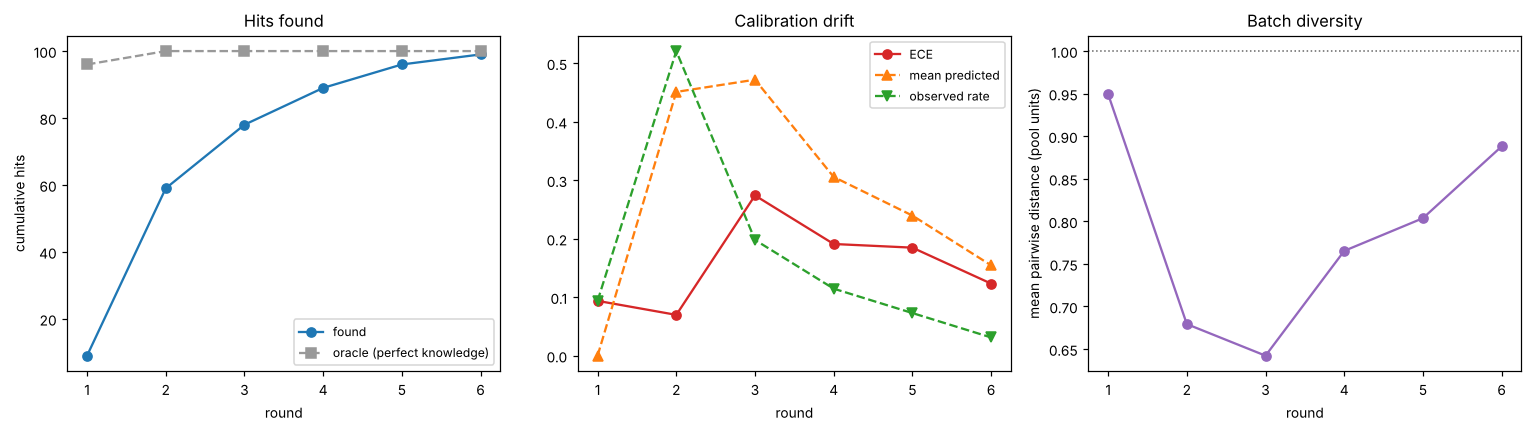

In [10]:
fig = report.plot()
FIGDIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGDIR / "01_hybrid_campaign_report.png", dpi=150, bbox_inches="tight")

## Three policies, head to head

One campaign tells you nothing about whether the policy was good -- you have no
counterfactual. The replay harness runs the same pool and the same model under
different policies, hiding all labels and revealing only selected batches.

Three seeds, because the spread between seeds is often as large as the gap
between policies. The shaded bands are the min-max envelope: **a gap smaller
than the bands is not a result.**

In [11]:
long_frame, results = compare_policies(
    pool.drop(columns=["latent_activity"]),
    label_col="label",
    model_factory=lambda: RandomForestClassifier(
        n_estimators=200, random_state=0, n_jobs=-1
    ),
    policies=["random", "greedy", "bald", "hybrid"],
    seeds=(0, 1, 2),
    feature_cols=feature_cols,
    id_col="item_id",
    budget=96,
    n_rounds=6,
    n_initial_labels=96,
    verbose=True,
)

[replay] policy=random seed=0


   random: 30/80 actives (37.5%) after 6 rounds of 96; final PR-AUC 0.529; rounds to 50% of actives: not reached; 6.7s
[replay] policy=random seed=1


   random: 29/78 actives (37.2%) after 6 rounds of 96; final PR-AUC 0.663; rounds to 50% of actives: not reached; 6.7s
[replay] policy=random seed=2


   random: 25/74 actives (33.8%) after 6 rounds of 96; final PR-AUC 0.742; rounds to 50% of actives: not reached; 6.7s
[replay] policy=greedy seed=0


   greedy: 75/80 actives (93.8%) after 6 rounds of 96; final PR-AUC 0.665; rounds to 50% of actives: 2; 6.5s
[replay] policy=greedy seed=1


...

   bald: 73/78 actives (93.6%) after 6 rounds of 96; final PR-AUC 0.701; rounds to 50% of actives: 2; 6.2s
[replay] policy=bald seed=2


   bald: 68/74 actives (91.9%) after 6 rounds of 96; final PR-AUC 0.770; rounds to 50% of actives: 2; 6.6s
[replay] policy=hybrid seed=0


   hybrid: 75/80 actives (93.8%) after 6 rounds of 96; final PR-AUC 0.615; rounds to 50% of actives: 2; 6.7s
[replay] policy=hybrid seed=1


   hybrid: 73/78 actives (93.6%) after 6 rounds of 96; final PR-AUC 0.621; rounds to 50% of actives: 2; 6.4s
[replay] policy=hybrid seed=2


   hybrid: 69/74 actives (93.2%) after 6 rounds of 96; final PR-AUC 0.792; rounds to 50% of actives: 2; 6.7s


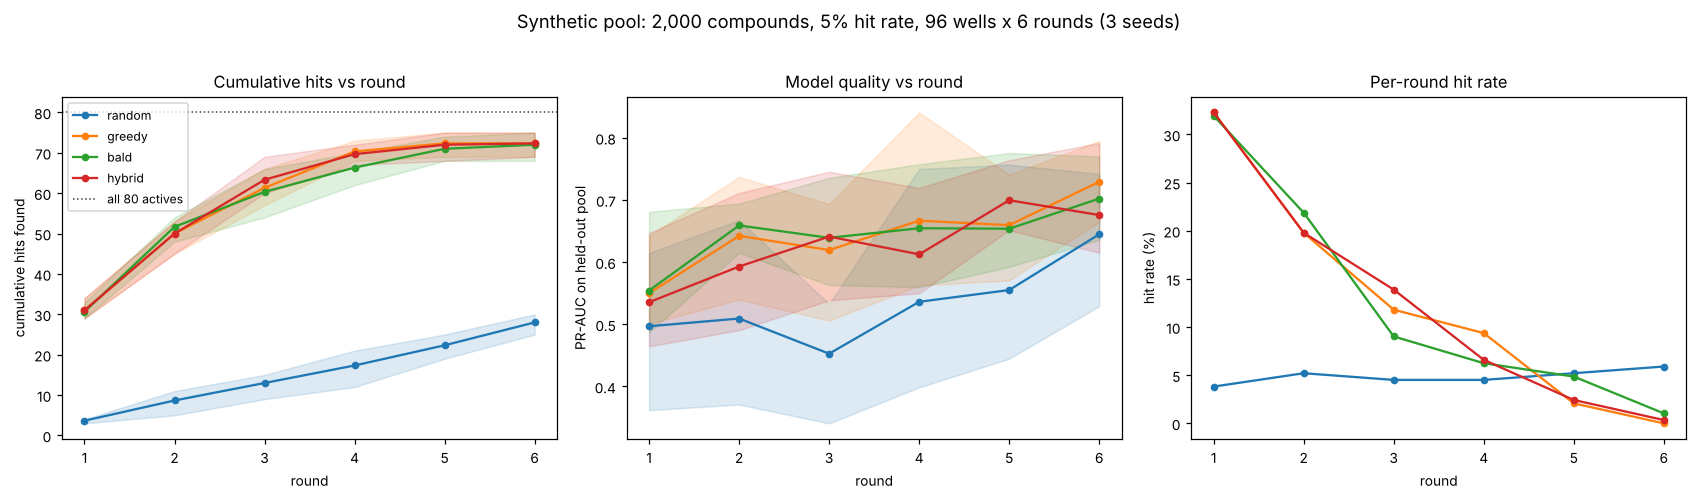

In [12]:
n_actives = results["greedy"][0].n_actives
fig = plot_comparison(
    long_frame,
    n_actives=n_actives,
    title="Synthetic pool: 2,000 compounds, 5% hit rate, 96 wells x 6 rounds (3 seeds)",
)
fig.savefig(FIGDIR / "01_policy_comparison.png", dpi=150, bbox_inches="tight")

In [13]:
final = long_frame[long_frame["round"] == long_frame["round"].max()]
summary = final.groupby("policy").agg(
    cumulative_hits=("cumulative_hits", "mean"),
    hits_sd=("cumulative_hits", "std"),
    fraction_found=("fraction_of_achievable", "mean"),
    final_pr_auc=("pr_auc", "mean"),
    pr_auc_sd=("pr_auc", "std"),
).round(3).sort_values("cumulative_hits", ascending=False)
summary

,cumulative_hits,hits_sd,fraction_found,final_pr_auc,pr_auc_sd
policy,,,,,
greedy,72.333,3.055,0.935,0.729,0.065
hybrid,72.333,3.055,0.935,0.676,0.101
bald,72.000,3.606,0.931,0.702,0.067
random,28.000,2.646,0.362,0.645,0.108


## The regret curve, and the thing it hides

Cumulative hits is the number a project leader asks for. It also hides the
mechanism, so look at the *per-round* hit rate: that is where the plateau lives.

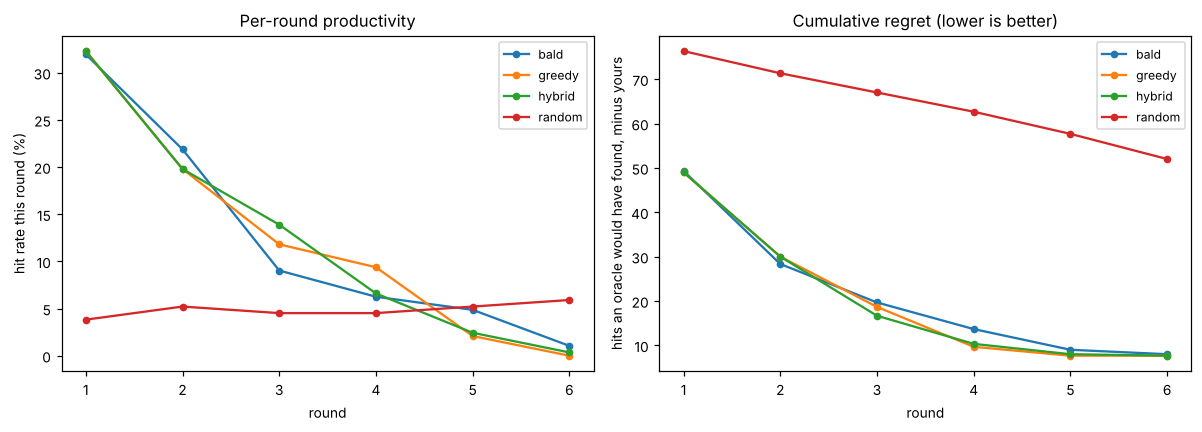

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for policy, group in long_frame.groupby("policy"):
    per_round = group.groupby("round")
    axes[0].plot(per_round["hit_rate"].mean().index,
                 per_round["hit_rate"].mean() * 100, "o-", label=policy, ms=4)
axes[0].set_xlabel("round"); axes[0].set_ylabel("hit rate this round (%)")
axes[0].set_title("Per-round productivity"); axes[0].legend(fontsize=8)

for policy, group in long_frame.groupby("policy"):
    per_round = group.groupby("round")["cumulative_hits"].mean()
    oracle = np.minimum(np.arange(1, len(per_round) + 1) * 96, n_actives)
    axes[1].plot(per_round.index, oracle - per_round.to_numpy(), "o-", label=policy, ms=4)
axes[1].set_xlabel("round"); axes[1].set_ylabel("hits an oracle would have found, minus yours")
axes[1].set_title("Cumulative regret (lower is better)"); axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGDIR / "01_regret_curves.png", dpi=150, bbox_inches="tight")

## What to take away

1. **Greedy is strong early.** It is not a straw man, and on an inexhaustible
   pool relative to your budget it can be very hard to beat on hits alone.
2. **Watch per-round productivity, not just the cumulative curve.** The
   cumulative curve is monotone and flatters whoever led early; the per-round
   rate is where a plateau shows up.
3. **Always include `random`.** It is the only line that tells you whether the
   features and model carry signal at all.
4. **Report seed spread.** With three seeds you can already see that some gaps
   here are not real.

Next: `02_replay_public_screen.ipynb` runs this comparison on real measured
screening data, where the answer is less flattering to the premise.